# Checkpoint 5 — Statistical Computing with R & Python
### Tecnólogo em Inteligência Artificial — FIAP · 2º Semestre
**Análise exploratória, descritiva e probabilística do dataset WINES**

| Integrante | RM (Matrícula) |
|---|---|
| Caio Ryan Velten Alves | 572913 |
| Carlos Alberto Oliveira Nascimento | 565694 |
| Davi França Aranda | 572751 |
| João Vitor Fernandes Gomes | 573882 |
| Murilo de Oliveira Moreira | 573534 |

---

**Objetivo.** Analisamos o teor alcoólico e a concentração de ácido málico dos vinhos por meio de distribuições de frequência, medidas descritivas e modelos probabilísticos.

| Etapa | Conteúdo | Seção |
|---|---|---|
| **Visualização** | Tabela de Distribuição de Frequências + Gráficos | Seção 3 |
| **Análise descritiva** | Tendência Central, Dispersão e Separatrizes (Quartis) | Seção 4 |
| **Análise probabilística** | Distribuição de Probabilidade + cálculos probabilísticos | Seção 5 |

## 1. Configuração do ambiente

Bibliotecas utilizadas:

- **pandas / numpy** → manipulação dos dados e cálculos numéricos;
- **matplotlib / seaborn** → gráficos;
- **scipy.stats** → distribuições de probabilidade, testes de aderência e medidas de forma.

In [1]:
# ---------------------------------------------------------------------------
# Importação das bibliotecas
# ---------------------------------------------------------------------------
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Mantemos os avisos do ambiente visíveis durante a execução.

# Configurações de exibição: 4 casas decimais nas tabelas e gráficos padronizados
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

# Cores fixas por variável: cada variável mantém a mesma cor em TODOS os gráficos,
# o que facilita a leitura (azul = Álcool, laranja = Ácido Málico).
COR = {"Alcohol": "#2a6fdb", "Malic.acid": "#e07b24"}

## 2. Carregamento e inspeção dos dados

Utilizamos o arquivo `wine.csv`, com 178 vinhos, 13 medições químicas e a coluna
`Wine`, que identifica três cultivares. Os dados estão disponíveis no
[dataset WINES](https://gist.github.com/tijptjik/9408623).

Na leitura, padronizamos os nomes alternativos das colunas para manter a mesma
identificação das variáveis ao longo da análise.

In [2]:
# ---------------------------------------------------------------------------
# Leitura do dataset
# ---------------------------------------------------------------------------
df = pd.read_csv("wine.csv")

# Padronização de nomes: se o arquivo for a versão do Kaggle, renomeamos as
# colunas para o mesmo padrão da versão do GitHub. Assim o notebook roda com
# nomes alternativos de colunas das versões do dataset.
MAPA_KAGGLE = {"Malic_Acid": "Malic.acid", "Ash_Alcanity": "Acl", "Magnesium": "Mg",
               "Total_Phenols": "Phenols", "Nonflavanoid_Phenols": "Nonflavanoid.phenols",
               "Proanthocyanins": "Proanth", "Color_Intensity": "Color.int", "OD280": "OD"}
df = df.rename(columns=MAPA_KAGGLE)

print(f"Dimensão do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Dimensão do dataset: 178 linhas x 14 colunas


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.2300,1.7100,2.4300,15.6000,127,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065
1,1,13.2000,1.7800,2.1400,11.2000,100,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050
2,1,13.1600,2.3600,2.6700,18.6000,101,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185
3,1,14.3700,1.9500,2.5000,16.8000,113,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480
4,1,13.2400,2.5900,2.8700,21.0000,118,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735


In [3]:
# ---------------------------------------------------------------------------
# Qualidade dos dados: tipos, valores nulos e linhas duplicadas
# ---------------------------------------------------------------------------
qualidade = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
})
print(f"Total de valores nulos: {df.isna().sum().sum()}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
qualidade

# INTERPRETAÇÃO:
# - O dataset tem 178 vinhos e 14 colunas: 13 medições químicas quantitativas
#   + a coluna 'Wine' (cultivar 1, 2 ou 3), que é QUALITATIVA (um rótulo) e,
#   por isso, não entra como variável de análise.
# - Não há valores nulos nem linhas duplicadas -> nenhuma imputação ou limpeza
#   é necessária; podemos usar as 178 observações na íntegra (n = 178).

Total de valores nulos: 0
Linhas duplicadas: 0


,tipo,nulos,valores_distintos
Wine,int64,0,3
Alcohol,float64,0,126
Malic.acid,float64,0,133
Ash,float64,0,79
Acl,float64,0,63
Mg,int64,0,53
Phenols,float64,0,97
Flavanoids,float64,0,132
Nonflavanoid.phenols,float64,0,39
Proanth,float64,0,101


### 2.1 Escolha das variáveis quantitativas

| Variável | Significado | Tipo | Justificativa |
|---|---|---|---|
| `Alcohol` | Teor alcoólico (% vol.) | Quantitativa contínua | Descreve o perfil alcoólico e permite comparar os vinhos. |
| `Malic.acid` | Concentração de ácido málico | Quantitativa contínua | Descreve um componente da acidez e apresenta maior dispersão relativa. |

O teor alcoólico apresenta distribuição aproximadamente simétrica, enquanto o
ácido málico tem assimetria à direita. Comparamos como essas diferenças se
refletem nas medidas descritivas e nos modelos Normal e Log-Normal.

A fonte não documenta a unidade de ácido málico. Apresentamos os valores
na escala do dataset, sem equiparar essa concentração a acidez total ou pH.

In [4]:
# ---------------------------------------------------------------------------
# Separando as variáveis de interesse
# ---------------------------------------------------------------------------
VARIAVEIS = ["Alcohol", "Malic.acid"]
NOMES = {"Alcohol": "Teor Alcoólico (% vol.)", "Malic.acid": "Ácido Málico (escala do dataset)"}

alcool = df["Alcohol"]
acido = df["Malic.acid"]

df[VARIAVEIS].describe().T

# INTERPRETAÇÃO (visão geral):
# - Alcohol: varia de 11,03% a 14,83%. Média (13,00) e mediana (13,05) quase
#   iguais -> primeiro indício de distribuição SIMÉTRICA.
# - Malic.acid: varia de 0,74 a 5,80. A média (2,34) é bem MAIOR que a
#   mediana (1,87) -> indício de ASSIMETRIA À DIREITA (poucos vinhos com
#   acidez muito alta "puxam" a média para cima).

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0000,13.0006,0.8118,11.0300,12.3625,13.0500,13.6775,14.8300
Malic.acid,178.0000,2.3363,1.1171,0.7400,1.6025,1.8650,3.0825,5.8000


## 3. Visualização dos Dados — Tabela de Distribuição de Frequências e Gráficos

### 3.1 Metodologia da tabela

Como as variáveis são **contínuas**, os valores são agrupados em **classes (intervalos)**:

1. **Número de classes (k)** pela **Regra de Sturges**: $k = 1 + 3{,}322 \cdot \log_{10}(n)$, arredondado para cima.
2. **Amplitude total**: $A_t = x_{max} - x_{min}$.
3. **Amplitude de classe**: $h = A_t / k$, arredondada **para cima** (garante que o maior valor caia dentro da última classe).
4. Classes no formato **[Li ; Ls)** — fechadas à esquerda e abertas à direita (padrão ⊢ da estatística).

Colunas da tabela:

| Coluna | Significado |
|---|---|
| **xi** | Ponto médio da classe (representa a classe nos cálculos com dados agrupados) |
| **fi** | Frequência absoluta — quantos vinhos caem na classe |
| **fri (%)** | Frequência relativa — fi / n × 100 |
| **Fi** | Frequência absoluta acumulada |
| **Fri (%)** | Frequência relativa acumulada |

In [5]:
# ---------------------------------------------------------------------------
# Função que monta a Tabela de Distribuição de Frequências (dados agrupados)
# ---------------------------------------------------------------------------
def tabela_frequencia(serie: pd.Series, casas: int = 2):
    '''
    Entrada : série numérica contínua.
    Processo: calcula k (Sturges), a amplitude de classe h e conta quantos
              valores caem em cada classe [Li ; Ls).
    Saída   : (tabela de frequências, limites das classes, k, h)
    '''
    n = serie.count()
    k = math.ceil(1 + 3.322 * math.log10(n))                 # Regra de Sturges
    amplitude_total = serie.max() - serie.min()
    fator = 10 ** casas
    h = math.ceil(amplitude_total / k * fator) / fator       # arredonda PARA CIMA
    limites = np.round(serie.min() + np.arange(k + 1) * h, casas)

    # right=False -> intervalos [Li ; Ls): o limite inferior pertence à classe
    classes = pd.cut(serie, bins=limites, right=False)
    fi = classes.value_counts(sort=False).values

    tabela = pd.DataFrame({
        "Classe": [f"{limites[i]:.{casas}f} ⊢ {limites[i+1]:.{casas}f}" for i in range(k)],
        "xi": (limites[:-1] + limites[1:]) / 2,
        "fi": fi,
        "fri (%)": fi / n * 100,
        "Fi": np.cumsum(fi),
        "Fri (%)": np.cumsum(fi) / n * 100,
    })
    # Linha de total para conferência (soma de fi deve ser n; soma de fri, 100%)
    total = pd.DataFrame({"Classe": ["TOTAL"], "xi": [np.nan], "fi": [fi.sum()],
                          "fri (%)": [fi.sum() / n * 100], "Fi": [np.nan], "Fri (%)": [np.nan]})
    tabela = pd.concat([tabela, total], ignore_index=True)
    return tabela, limites, k, h


def exibir(tabela):
    '''Formata a tabela para leitura (sem casas decimais em contagens).'''
    return (tabela.style
            .format({"xi": "{:.3f}", "fi": "{:.0f}", "fri (%)": "{:.2f}",
                     "Fi": "{:.0f}", "Fri (%)": "{:.2f}"}, na_rep="—")
            .hide(axis="index")
            .set_properties(**{"text-align": "center"}))

### 3.2 Tabela de Frequências — Teor Alcoólico (`Alcohol`)

In [6]:
tab_alc, lim_alc, k_alc, h_alc = tabela_frequencia(alcool)
print(f"n = {alcool.count()} | k (Sturges) = {k_alc} classes | "
      f"Amplitude total = {alcool.max() - alcool.min():.2f} | h = {h_alc}")
exibir(tab_alc)

# INTERPRETAÇÃO — Teor Alcoólico:
# - Sturges: k = 1 + 3,322*log10(178) = 8,47 -> 9 classes de amplitude 0,43%.
# - As classes centrais [12,32 ; 13,18) concentram a maior frequência
#   (30 + 30 = 60 vinhos, 33,7% do total) e as frequências DIMINUEM de forma
#   parecida para os dois lados -> distribuição aproximadamente SIMÉTRICA.
# - As caudas são leves: só 3 vinhos (1,7%) abaixo de 11,46% e só 2 vinhos
#   (1,1%) a partir de 14,47%.
# - Pela Fri, 39,9% dos vinhos têm teor alcoólico abaixo de 12,75%, 56,7%
#   abaixo de 13,18% e 88,2% abaixo de 14,04%; 98,9% ficam abaixo de 14,47%.
# - Observação: o topo é "achatado" (várias classes com 28-30 vinhos), e não
#   um pico estreito. Isso sugere mistura de subgrupos (os 3 cultivares),
#   padrão também observado nas medidas por cultivar.

n = 178 | k (Sturges) = 9 classes | Amplitude total = 3.80 | h = 0.43


Classe,xi,fi,fri (%),Fi,Fri (%)
11.03 ⊢ 11.46,11.245,3,1.69,3,1.69
11.46 ⊢ 11.89,11.675,15,8.43,18,10.11
11.89 ⊢ 12.32,12.105,23,12.92,41,23.03
12.32 ⊢ 12.75,12.535,30,16.85,71,39.89
12.75 ⊢ 13.18,12.965,30,16.85,101,56.74
13.18 ⊢ 13.61,13.395,28,15.73,129,72.47
13.61 ⊢ 14.04,13.825,28,15.73,157,88.20
14.04 ⊢ 14.47,14.255,19,10.67,176,98.88
14.47 ⊢ 14.90,14.685,2,1.12,178,100.00
TOTAL,—,178,100.00,—,—


### 3.3 Tabela de Frequências — Ácido Málico (`Malic.acid`)

In [7]:
tab_mal, lim_mal, k_mal, h_mal = tabela_frequencia(acido)
print(f"n = {acido.count()} | k (Sturges) = {k_mal} classes | "
      f"Amplitude total = {acido.max() - acido.min():.2f} | h = {h_mal}")
exibir(tab_mal)

# INTERPRETAÇÃO — Ácido Málico:
# - 9 classes de amplitude 0,57.
# - A classe modal [1,31 ; 1,88) concentra sozinha 70 vinhos (39,3%): a
#   maioria dos vinhos tem acidez málica BAIXA.
# - Pela Fri, 51,1% dos vinhos têm menos de 1,88 e 64,6% menos de 2,45.
# - Após o pico, as frequências caem e formam uma CAUDA LONGA À DIREITA
#   (16, 16, 17, 8, 3, 3): poucos vinhos com acidez muito alta (até 5,80).
#   -> distribuição ASSIMÉTRICA POSITIVA (à direita).
# - Há um pequeno "platô" entre 2,45 e 4,16 (16-17 vinhos por classe),
#   indicando heterogeneidade na concentração de ácido málico.

n = 178 | k (Sturges) = 9 classes | Amplitude total = 5.06 | h = 0.57


Classe,xi,fi,fri (%),Fi,Fri (%)
0.74 ⊢ 1.31,1.025,21,11.80,21,11.80
1.31 ⊢ 1.88,1.595,70,39.33,91,51.12
1.88 ⊢ 2.45,2.165,24,13.48,115,64.61
2.45 ⊢ 3.02,2.735,16,8.99,131,73.60
3.02 ⊢ 3.59,3.305,16,8.99,147,82.58
3.59 ⊢ 4.16,3.875,17,9.55,164,92.13
4.16 ⊢ 4.73,4.445,8,4.49,172,96.63
4.73 ⊢ 5.30,5.015,3,1.69,175,98.31
5.30 ⊢ 5.87,5.585,3,1.69,178,100.00
TOTAL,—,178,100.00,—,—


### 3.4 Gráficos — Histograma com Polígono de Frequências e Ogiva

- **Histograma + polígono de frequências:** mostram a **forma** da distribuição (simetria, pico, caudas). Usamos exatamente as mesmas classes das tabelas, para que gráfico e tabela sejam coerentes.
- **Ogiva (frequência acumulada):** permite ler diretamente "quantos % dos vinhos estão abaixo de um valor" — é a versão gráfica da coluna **Fri**.

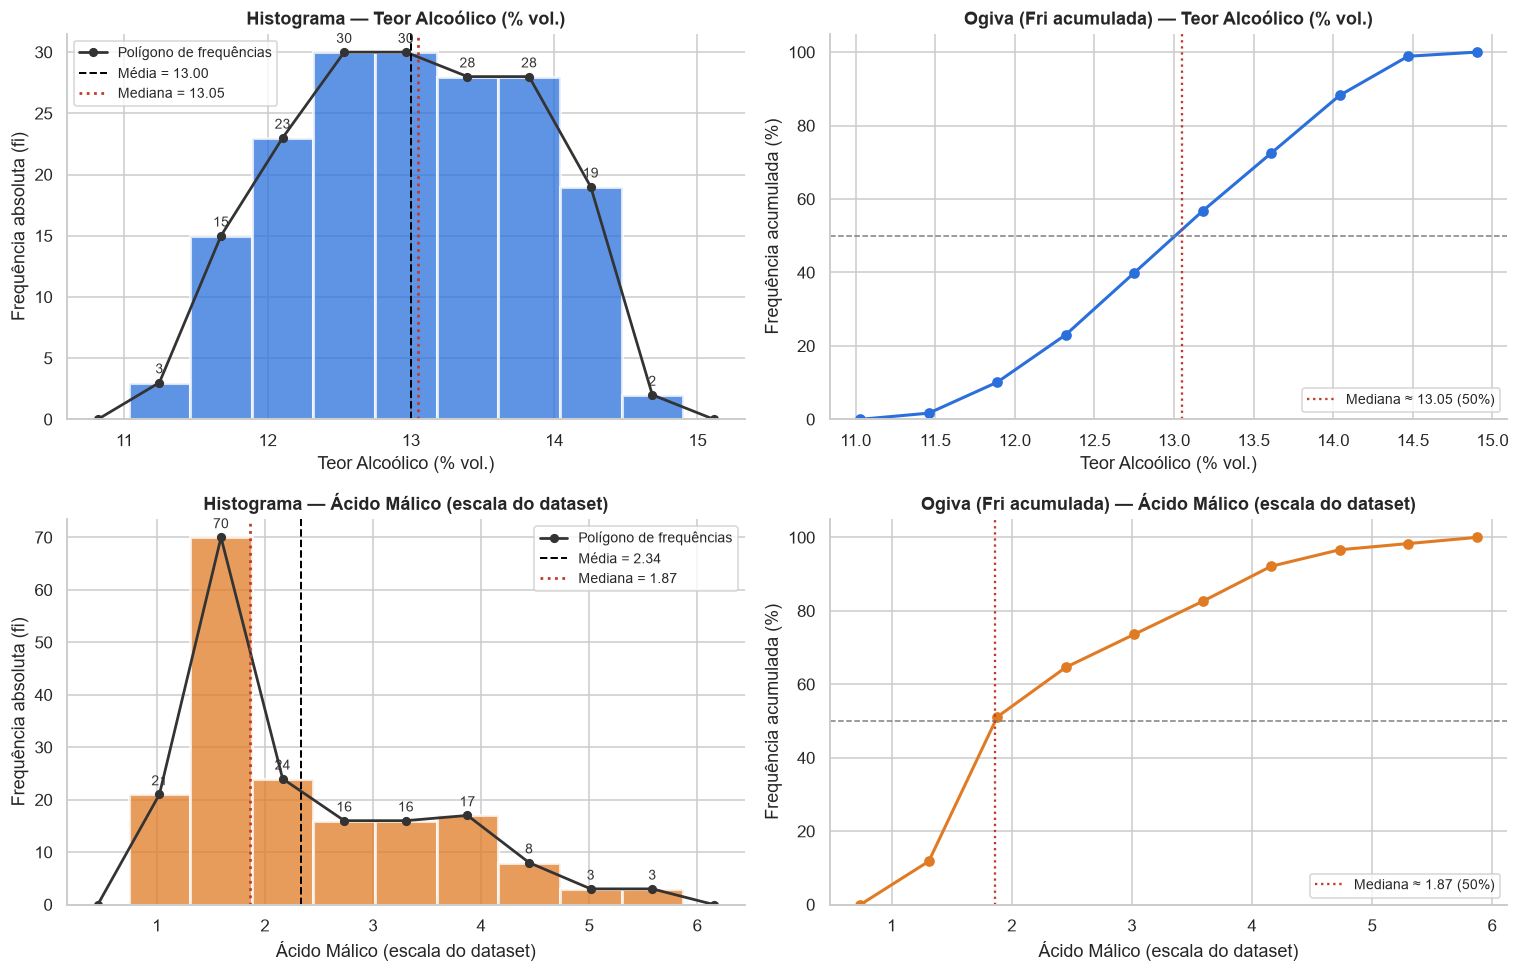

In [8]:
# ---------------------------------------------------------------------------
# Painel de gráficos: linha 1 = Álcool | linha 2 = Ácido Málico
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for linha, (var, lim, tab) in enumerate([("Alcohol", lim_alc, tab_alc),
                                         ("Malic.acid", lim_mal, tab_mal)]):
    serie, cor = df[var], COR[var]
    t = tab.iloc[:-1]  # remove a linha TOTAL

    # (1) Histograma com as MESMAS classes da tabela + polígono de frequências
    ax = axes[linha, 0]
    ax.hist(serie, bins=lim, color=cor, alpha=0.75, edgecolor="white", linewidth=2)
    # Polígono: liga os pontos médios; fecha no eixo com classes fictícias de fi=0
    h = lim[1] - lim[0]
    xs = np.r_[t["xi"].iloc[0] - h, t["xi"], t["xi"].iloc[-1] + h]
    ys = np.r_[0, t["fi"], 0]
    ax.plot(xs, ys, color="#333333", marker="o", markersize=5, linewidth=1.8,
            label="Polígono de frequências")
    for x, y in zip(t["xi"], t["fi"]):
        ax.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 6),
                    ha="center", fontsize=9, color="#333333")
    ax.axvline(serie.mean(), color="black", linestyle="--", linewidth=1.3,
               label=f"Média = {serie.mean():.2f}")
    ax.axvline(serie.median(), color="#c0392b", linestyle=":", linewidth=1.8,
               label=f"Mediana = {serie.median():.2f}")
    ax.set_title(f"Histograma — {NOMES[var]}")
    ax.set_xlabel(NOMES[var]); ax.set_ylabel("Frequência absoluta (fi)")
    ax.legend(fontsize=9)

    # (2) Ogiva: frequência relativa acumulada no limite SUPERIOR de cada classe
    ax = axes[linha, 1]
    ax.plot(lim, np.r_[0, t["Fri (%)"]], color=cor, marker="o", linewidth=2)
    ax.axhline(50, color="gray", linestyle="--", linewidth=1)
    ax.axvline(serie.median(), color="#c0392b", linestyle=":", linewidth=1.5,
               label=f"Mediana ≈ {serie.median():.2f} (50%)")
    ax.set_title(f"Ogiva (Fri acumulada) — {NOMES[var]}")
    ax.set_xlabel(NOMES[var]); ax.set_ylabel("Frequência acumulada (%)")
    ax.set_ylim(0, 105); ax.legend(fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()

# INTERPRETAÇÃO DOS GRÁFICOS:
# - Álcool (linha de cima): histograma em forma de "sino achatado", com
#   média (13,00) e mediana (13,05) praticamente sobrepostas -> SIMETRIA.
#   A ogiva tem formato de "S" suave e cruza 50% perto de 13,0%.
# - Ácido Málico (linha de baixo): pico bem à esquerda (1,31-1,88) e cauda
#   longa à direita. A média (2,34) fica À DIREITA da mediana (1,87): quando
#   média > mediana, a distribuição é assimétrica POSITIVA.
#   A ogiva sobe muito rápido no início (51% dos vinhos já estão abaixo de
#   1,88) e depois cresce devagar -> a maior parte dos vinhos é pouco ácida.

## 4. Análise Descritiva dos Dados

Organizamos as medidas em três grupos:

| Grupo | Medidas | O que responde |
|---|---|---|
| **Tendência Central** | Média, Mediana, Moda | "Qual é o valor típico?" |
| **Dispersão** | Amplitude, Variância, Desvio-padrão, Coeficiente de Variação, Desvio Médio Absoluto, Amplitude Interquartil | "Quanto os valores variam em torno do típico?" |
| **Separatrizes** | Quartis (Q1, Q2, Q3), Decis e Percentis | "Como os dados se dividem em partes iguais?" |
| **Forma** (complemento) | Assimetria e Curtose | "Qual o formato da distribuição?" |

> **Por que variância com n − 1?** Os 178 vinhos são uma **amostra** de todos os vinhos da região. Dividir por *n − 1* (correção de Bessel) gera um estimador **não viesado** da variância populacional. No pandas isso é o padrão (`ddof=1`).

In [9]:
# ---------------------------------------------------------------------------
# Função de medidas descritivas (dados brutos, não agrupados)
# ---------------------------------------------------------------------------
def medidas_descritivas(s: pd.Series) -> pd.Series:
    '''
    Entrada : série numérica.
    Saída   : série com todas as medidas de tendência central, dispersão,
              separatrizes e forma, calculadas sobre os dados brutos.
    '''
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    modas = s.mode()
    return pd.Series({
        # --- Tendência central ---
        "Média": s.mean(),
        "Mediana": s.median(),
        "Moda (dados brutos)": ", ".join(f"{m:.2f}" for m in modas),
        # --- Dispersão ---
        "Mínimo": s.min(),
        "Máximo": s.max(),
        "Amplitude total": s.max() - s.min(),
        "Variância amostral (s²)": s.var(ddof=1),
        "Desvio-padrão (s)": s.std(ddof=1),
        "Coef. de Variação (%)": s.std(ddof=1) / s.mean() * 100,
        "Desvio Médio Absoluto": (s - s.mean()).abs().mean(),
        # --- Separatrizes ---
        "Q1 (25%)": q1,
        "Q2 (50%) = Mediana": q2,
        "Q3 (75%)": q3,
        "Amplitude Interquartil (IQR)": q3 - q1,
        "D1 / P10 (10%)": s.quantile(0.10),
        "D9 / P90 (90%)": s.quantile(0.90),
        # --- Forma ---
        "Assimetria (Fisher)": stats.skew(s, bias=False),
        "Curtose (excesso)": stats.kurtosis(s, bias=False),
    })

descritiva = pd.DataFrame({NOMES[v]: medidas_descritivas(df[v]) for v in VARIAVEIS})
descritiva

,Teor Alcoólico (% vol.),Ácido Málico (escala do dataset)
Média,13.0006,2.3363
Mediana,13.0500,1.8650
Moda (dados brutos),"12.37, 13.05",1.73
Mínimo,11.0300,0.7400
Máximo,14.8300,5.8000
Amplitude total,3.8000,5.0600
Variância amostral (s²),0.6591,1.2480
Desvio-padrão (s),0.8118,1.1171
Coef. de Variação (%),6.2445,47.8159
Desvio Médio Absoluto,0.6885,0.9203


### 4.1 Medidas de Tendência Central

In [10]:
# ---------------------------------------------------------------------------
# Tendência central: dados brutos x dados agrupados (tabela de frequências)
# ---------------------------------------------------------------------------
def medidas_agrupadas(tabela: pd.DataFrame, limites: np.ndarray) -> dict:
    '''
    Calcula média, mediana e moda (fórmula de Czuber) a partir da TABELA de
    frequências. A comparação com as medidas brutas permite avaliar a
    aproximação introduzida pelos intervalos de classe.
    '''
    t = tabela.iloc[:-1]                               # remove linha TOTAL
    fi, xi = t["fi"].values, t["xi"].values
    Fi, n, h = np.cumsum(fi), fi.sum(), limites[1] - limites[0]

    media = (fi * xi).sum() / n                        # média ponderada pelos pontos médios

    i = np.argmax(Fi >= n / 2)                         # classe mediana (onde Fi atinge n/2)
    F_ant = Fi[i - 1] if i > 0 else 0
    mediana = limites[i] + (n / 2 - F_ant) / fi[i] * h

    # Moda de Czuber: Mo = Li + d1 / (d1 + d2) * h
    # (d1 = fi da classe modal - fi anterior ; d2 = fi da classe modal - fi posterior)
    modas = []
    for j in np.where(fi == fi.max())[0]:              # trata empate de classes modais
        d1 = fi[j] - (fi[j - 1] if j > 0 else 0)
        d2 = fi[j] - (fi[j + 1] if j < len(fi) - 1 else 0)
        modas.append(limites[j] + d1 / (d1 + d2) * h)
    return {"Média": media, "Mediana": mediana, "Moda (Czuber)": sorted(set(np.round(modas, 4)))}

comparacao = pd.DataFrame({
    NOMES["Alcohol"]: {"Média (bruta)": alcool.mean(), "Mediana (bruta)": alcool.median(),
                       **{k + " agrupada": v for k, v in medidas_agrupadas(tab_alc, lim_alc).items()}},
    NOMES["Malic.acid"]: {"Média (bruta)": acido.mean(), "Mediana (bruta)": acido.median(),
                          **{k + " agrupada": v for k, v in medidas_agrupadas(tab_mal, lim_mal).items()}},
})
comparacao

# INTERPRETAÇÃO — TENDÊNCIA CENTRAL:
#
# Teor Alcoólico:
# - Média = 13,00% | Mediana = 13,05% | Moda de Czuber = 12,75%.
# - Média ≈ mediana (diferença de 0,05 ponto) -> distribuição SIMÉTRICA; aqui
#   a MÉDIA é uma boa medida do "vinho típico": ~13% de álcool.
# - Moda nos dados brutos: 12,37 e 13,05 (cada valor aparece 6 vezes). Em
#   variável contínua a moda bruta é pouco informativa (depende de valores
#   repetidos por arredondamento), por isso usamos a moda de Czuber.
#   Há duas classes modais empatadas (30 vinhos cada) e, nas duas, a fórmula
#   de Czuber aponta para o mesmo ponto: 12,75% (a fronteira entre elas).
#
# Ácido Málico:
# - Média = 2,34 | Mediana = 1,87 | Moda (bruta) = 1,73 | Moda de Czuber = 1,60.
# - Moda < Mediana < Média -> padrão clássico de ASSIMETRIA POSITIVA.
# - A média é "puxada" pela cauda direita (vinhos muito ácidos). Para descrever
#   o vinho típico, a MEDIANA (1,87) é a medida mais representativa:
#   metade dos vinhos tem até 1,87 de ácido málico.
#
# Comparação das medidas: média e mediana agrupadas ficaram
# praticamente iguais às brutas (diferenças de no máximo 0,04) -> as 9 classes
# de Sturges representam bem os dados originais.

,Teor Alcoólico (% vol.),Ácido Málico (escala do dataset)
Média (bruta),13.0006,2.3363
Mediana (bruta),13.0500,1.8650
Média agrupada,13.0037,2.3315
Mediana agrupada,13.0080,1.8637
Moda (Czuber) agrupada,[12.75],[1.604]


### 4.2 Medidas de Dispersão

In [11]:
# ---------------------------------------------------------------------------
# Dispersão: absoluta e relativa
# ---------------------------------------------------------------------------
dispersao = descritiva.loc[["Amplitude total", "Variância amostral (s²)", "Desvio-padrão (s)",
                            "Coef. de Variação (%)", "Desvio Médio Absoluto",
                            "Amplitude Interquartil (IQR)"]].astype(float)
dispersao

# INTERPRETAÇÃO — DISPERSÃO:
#
# Teor Alcoólico:
# - Desvio-padrão = 0,81 ponto percentual: em média, os vinhos se afastam
#   ~0,8% da média de 13%.
# - CV = 6,24% (< 15%) -> BAIXA dispersão relativa: os vinhos são bastante
#   HOMOGÊNEOS em teor alcoólico.
# - Amplitude = 3,80 (de 11,03% a 14,83%).
#
# Ácido Málico:
# - Desvio-padrão = 1,12, quase metade da própria média.
# - CV = 47,82% (> 30%) -> ALTA dispersão relativa: os vinhos são muito
#   HETEROGÊNEOS em acidez málica.
# - Amplitude = 5,06: o vinho mais ácido tem ~7,8x mais ácido málico que
#   o menos ácido (5,80 / 0,74).
#
# Por que usar o CV para comparar? As variáveis têm unidades e escalas
# diferentes (% de álcool x de ácido). O desvio-padrão sozinho não permite
# comparar; o CV é adimensional (em %) e mostra que o ÁCIDO MÁLICO varia
# ~7,7x mais que o ÁLCOOL em termos relativos (47,82% / 6,24%).
#
# Referência usual para o CV: <= 15% baixa | 15% a 30% média | > 30% alta.

,Teor Alcoólico (% vol.),Ácido Málico (escala do dataset)
Amplitude total,3.8000,5.0600
Variância amostral (s²),0.6591,1.2480
Desvio-padrão (s),0.8118,1.1171
Coef. de Variação (%),6.2445,47.8159
Desvio Médio Absoluto,0.6885,0.9203
Amplitude Interquartil (IQR),1.3150,1.4800


### 4.3 Medidas Separatrizes (Quartis) e Boxplot

Os **quartis** dividem os dados ordenados em 4 partes com 25% das observações cada. Com eles calculamos:

- **IQR = Q3 − Q1** (amplitude interquartil): a variação dos 50% centrais, **robusta a outliers**;
- **Cercas de Tukey**: $Q1 - 1{,}5 \cdot IQR$ e $Q3 + 1{,}5 \cdot IQR$. Valores fora delas são considerados **outliers** (valores atípicos).

In [12]:
# ---------------------------------------------------------------------------
# Quartis, IQR, cercas de Tukey e detecção de outliers
# ---------------------------------------------------------------------------
linhas = []
for var in VARIAVEIS:
    s = df[var]
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    cerca_inf, cerca_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = s[(s < cerca_inf) | (s > cerca_sup)].sort_values()
    linhas.append({
        "Variável": NOMES[var], "Q1": q1, "Q2 (Mediana)": q2, "Q3": q3, "IQR": iqr,
        "Q2 - Q1": q2 - q1, "Q3 - Q2": q3 - q2,
        "Cerca inferior": cerca_inf, "Cerca superior": cerca_sup,
        "Nº outliers": len(outliers),
        "Outliers": ", ".join(f"{v:.2f}" for v in outliers) or "nenhum",
    })
quartis = pd.DataFrame(linhas).set_index("Variável")
quartis.T

Variável,Teor Alcoólico (% vol.),Ácido Málico (escala do dataset)
Q1,12.3625,1.6025
Q2 (Mediana),13.0500,1.8650
Q3,13.6775,3.0825
IQR,1.3150,1.4800
Q2 - Q1,0.6875,0.2625
Q3 - Q2,0.6275,1.2175
Cerca inferior,10.3900,-0.6175
Cerca superior,15.6500,5.3025
Nº outliers,0,3
Outliers,nenhum,"5.51, 5.65, 5.80"


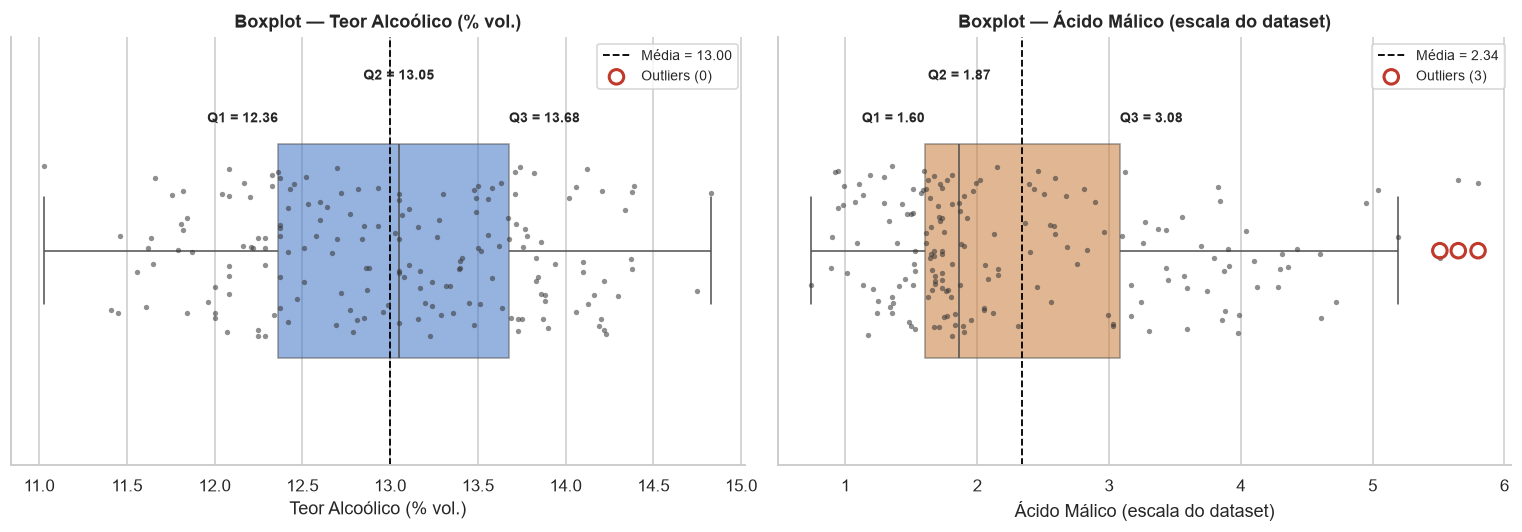

In [13]:
# ---------------------------------------------------------------------------
# Boxplot + distribuição dos pontos (strip plot) para cada variável
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, var in zip(axes, VARIAVEIS):
    s = df[var]
    sns.boxplot(x=s, ax=ax, color=COR[var], width=0.45, fliersize=0,
                boxprops={"alpha": 0.55})
    sns.stripplot(x=s, ax=ax, color="#333333", size=3.5, alpha=0.55, jitter=0.18)
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    # Rótulos dos quartis em alturas/alinhamentos diferentes para não se sobreporem
    for valor, rotulo, y, alinh in [(q1, "Q1", -0.27, "right"), (q2, "Q2", -0.36, "center"),
                                    (q3, "Q3", -0.27, "left")]:
        ax.annotate(f"{rotulo} = {valor:.2f}", (valor, y), ha=alinh, fontsize=9,
                    fontweight="bold")
    ax.axvline(s.mean(), color="black", linestyle="--", linewidth=1.2,
               label=f"Média = {s.mean():.2f}")
    iqr = q3 - q1
    outl = s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]
    ax.scatter(outl, np.zeros(len(outl)), s=90, facecolors="none", edgecolors="#c0392b",
               linewidths=2, zorder=5, label=f"Outliers ({len(outl)})")
    ax.set_title(f"Boxplot — {NOMES[var]}")
    ax.set_xlabel(NOMES[var]); ax.set_ylim(0.45, -0.45)
    ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

# INTERPRETAÇÃO — SEPARATRIZES (QUARTIS):
#
# Teor Alcoólico: Q1 = 12,36 | Q2 = 13,05 | Q3 = 13,68 | IQR = 1,32
# - 25% dos vinhos têm até 12,36% de álcool; 75% têm até 13,68%.
# - Os 50% centrais estão entre 12,36% e 13,68% (faixa de só 1,32 ponto).
# - Distâncias Q2-Q1 (0,69) e Q3-Q2 (0,63) quase iguais -> caixa simétrica.
# - Cercas: [10,39 ; 15,65] -> NENHUM outlier. Todos os teores alcoólicos são
#   plausíveis e o conjunto é bem comportado.
#
# Ácido Málico: Q1 = 1,60 | Q2 = 1,87 | Q3 = 3,08 | IQR = 1,48
# - 50% dos vinhos têm entre 1,60 e 3,08.
# - Q2-Q1 = 0,26, mas Q3-Q2 = 1,22 (4,6x maior): a metade SUPERIOR dos dados
#   é muito mais espalhada -> confirma a assimetria à direita.
# - Cerca superior = 5,30 -> 3 OUTLIERS: 5,51 | 5,65 | 5,80.
#   São valores atípicos, sem evidência de erro de medição ou digitação.
#   Por isso mantemos essas observações: eles fazem parte da
#   variabilidade observada e contribuem para a descrição dos vinhos.

### 4.4 Medidas de Forma (Assimetria e Curtose)

Utilizamos assimetria e curtose para descrever a forma das distribuições e fundamentar a escolha dos modelos probabilísticos.

| Medida | Referência |
|---|---|
| **Assimetria** | ≈ 0 simétrica · > 0 cauda à direita · < 0 cauda à esquerda (|valor| < 0,5 ≈ simétrica) |
| **Curtose (excesso)** | ≈ 0 como a Normal (mesocúrtica) · > 0 pico alto/caudas pesadas (leptocúrtica) · < 0 achatada (platicúrtica) |

In [14]:
# ---------------------------------------------------------------------------
# Assimetria e curtose + coeficiente de assimetria de Pearson
# ---------------------------------------------------------------------------
forma = pd.DataFrame({
    NOMES[v]: {
        "Assimetria de Fisher (g1)": stats.skew(df[v], bias=False),
        "Assimetria de Pearson 3(média-mediana)/s": 3 * (df[v].mean() - df[v].median()) / df[v].std(),
        "Curtose (excesso, g2)": stats.kurtosis(df[v], bias=False),
    } for v in VARIAVEIS
})
forma

# INTERPRETAÇÃO — FORMA:
#
# Teor Alcoólico:
# - Assimetria = -0,05 (praticamente zero) -> SIMÉTRICA.
# - Curtose = -0,85 -> PLATICÚRTICA: a distribuição é mais "achatada" que a
#   Normal (topo largo, caudas curtas). Isso é coerente com o histograma, que
#   tem várias classes centrais com frequências parecidas (28 a 30 vinhos).
#
# Ácido Málico:
# - Assimetria = +1,04 (> 1) -> FORTEMENTE assimétrica à direita.
#   O coeficiente de Pearson (+1,27) confirma o mesmo diagnóstico.
# - Curtose = +0,30 -> próxima da Normal nesse aspecto.
#
# INTERPRETAÇÃO DOS MODELOS: o álcool é candidato natural a um modelo
# NORMAL; o ácido málico precisa de uma distribuição ASSIMÉTRICA (Log-Normal).

,Teor Alcoólico (% vol.),Ácido Málico (escala do dataset)
Assimetria de Fisher (g1),-0.0515,1.0397
Assimetria de Pearson 3(média-mediana)/s,-0.1825,1.2658
"Curtose (excesso, g2)",-0.8525,0.2992


### 4.5 Complemento: as medidas por cultivar

O dataset do GitHub informa o **cultivar** (tipo de uva) de cada vinho. Comparar as medidas por cultivar ajuda a **explicar** os padrões encontrados (topo achatado do álcool e o segundo grupo de alta acidez) e relacionar a variabilidade química aos cultivares.

Alcohol                        Malic.acid                     
       count    mean  median    std      count   mean median    std
Wine                                                               
1         59 13.7447 13.7500 0.4621         59 2.0107 1.7700 0.6885
2         71 12.2787 12.2900 0.5380         71 1.9327 1.6100 1.0156
3         48 13.1538 13.1650 0.5302         48 3.3338 3.2650 1.0879

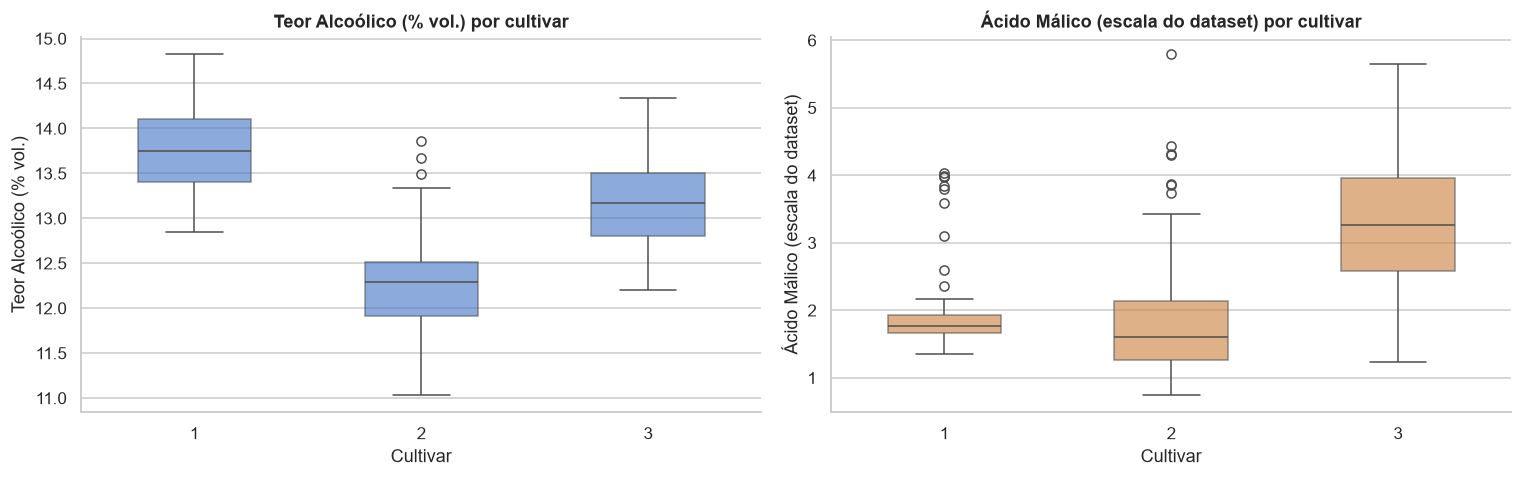

In [15]:
# ---------------------------------------------------------------------------
# Medidas descritivas por cultivar (coluna 'Wine')
# ---------------------------------------------------------------------------
if "Wine" in df.columns:
    por_cultivar = df.groupby("Wine")[VARIAVEIS].agg(["count", "mean", "median", "std"])
    display(por_cultivar)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, var in zip(axes, VARIAVEIS):
        sns.boxplot(data=df, x="Wine", y=var, ax=ax, color=COR[var], width=0.5,
                    boxprops={"alpha": 0.6})
        ax.set_title(f"{NOMES[var]} por cultivar"); ax.set_xlabel("Cultivar")
        ax.set_ylabel(NOMES[var])
    plt.tight_layout(); plt.show()
else:
    print("Arquivo sem a coluna 'Wine' (versão Kaggle): análise por cultivar não disponível.")

# INTERPRETAÇÃO:
# - Álcool: o cultivar 1 tem média de 13,74%, o cultivar 3 de 13,15% e o
#   cultivar 2 de 12,28%. São TRÊS "sinos" com centros diferentes somados ->
#   isso explica o topo achatado (curtose negativa) da distribuição geral.
# - Ácido málico: cultivares 1 e 2 têm medianas baixas (1,77 e 1,61),
#   enquanto o cultivar 3 tem mediana de 3,27 -> é ele que forma a cauda
#   direita e o "platô" de alta acidez visto na tabela de frequências.
# - Conclusão: a variabilidade das duas variáveis está ligada a GRUPOS
#   de vinhos com perfis diferentes, coerentes com os cultivares conhecidos.

## 5. Análise Probabilística

**Estratégia:**

1. **Escolher a distribuição de probabilidade** de cada variável com base na forma observada (seção 4.4);
2. **Verificar a aderência** do modelo aos dados (testes estatísticos + gráfico QQ + comparação visual);
3. **Realizar os cálculos probabilísticos** e **comparar** a probabilidade teórica (do modelo) com a frequência empírica (proporção real nos dados) — assim validamos se o modelo é confiável.

**Testes de aderência utilizados** (nível de significância α = 5%):

| Teste | H₀ (hipótese nula) | Decisão |
|---|---|---|
| **Shapiro-Wilk** | Os dados vêm de uma distribuição Normal | p < 0,05 → rejeita H₀ |
| **D'Agostino-Pearson** | Normalidade (baseado em assimetria + curtose) | p < 0,05 → rejeita H₀ |
| **Kolmogorov-Smirnov (KS)** | Distância entre distribuição empírica e ajustada | Avaliação descritiva; parâmetros estimados na amostra |

> **Observação técnica:** quando os parâmetros do modelo são estimados a partir dos próprios dados, o p-valor usual do KS não é calibrado para esse ajuste. Interpretamos a estatística KS de forma descritiva e fundamentamos a avaliação no QQ-plot e nas diferenças entre probabilidades teóricas e empíricas; as decisões formais de normalidade usam Shapiro-Wilk e D'Agostino-Pearson.

### 5.1 Teor Alcoólico — Distribuição Normal

**Por que Normal?** Variável contínua, simétrica (assimetria ≈ 0), sem outliers e com média ≈ mediana. O modelo é $X \sim N(\mu, \sigma)$, com parâmetros estimados pela amostra: $\hat\mu = \bar{x}$ e $\hat\sigma = s$.

In [16]:
# ---------------------------------------------------------------------------
# Ajuste da Normal e testes de aderência — Teor Alcoólico
# ---------------------------------------------------------------------------
mu_alc, sd_alc = alcool.mean(), alcool.std(ddof=1)
normal_alc = stats.norm(loc=mu_alc, scale=sd_alc)       # modelo X ~ N(13,00 ; 0,81)

testes_alc = pd.DataFrame({
    "Estatística": [stats.shapiro(alcool).statistic, stats.normaltest(alcool).statistic,
                    stats.kstest(alcool, normal_alc.cdf).statistic],
    "p-valor": [stats.shapiro(alcool).pvalue, stats.normaltest(alcool).pvalue,
                np.nan],
}, index=["Shapiro-Wilk", "D'Agostino-Pearson", "Kolmogorov-Smirnov"])
testes_alc["Decisão (α=5%)"] = np.where(testes_alc["p-valor"] < 0.05, "Rejeita H0", "Não rejeita H0")
testes_alc.loc["Kolmogorov-Smirnov", "Decisão (α=5%)"] = "Descritivo (parâmetros ajustados)"
print(f"Modelo: X ~ Normal(μ = {mu_alc:.4f}, σ = {sd_alc:.4f})")
testes_alc

Modelo: X ~ Normal(μ = 13.0006, σ = 0.8118)


,Estatística,p-valor,Decisão (α=5%)
Shapiro-Wilk,0.9818,0.0200,Rejeita H0
D'Agostino-Pearson,15.9636,0.0003,Rejeita H0
Kolmogorov-Smirnov,0.0679,NaN,Descritivo (parâmetros ajustados)


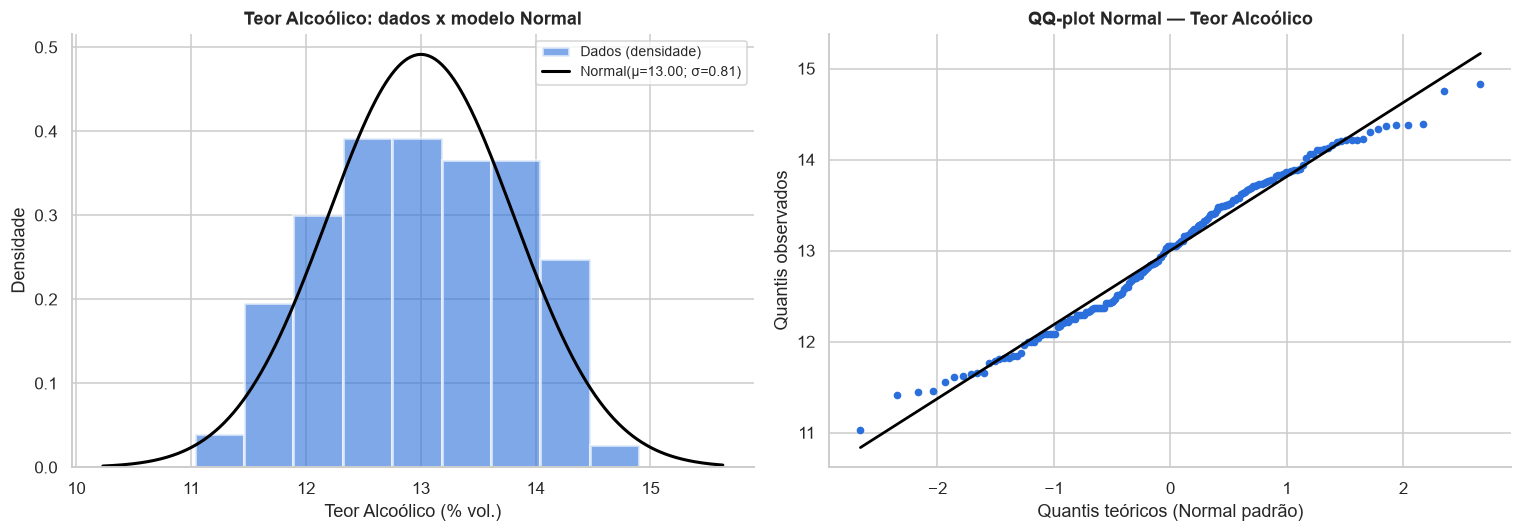

In [17]:
# ---------------------------------------------------------------------------
# Gráficos de aderência: histograma x curva Normal | QQ-plot
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(alcool, bins=lim_alc, density=True, color=COR["Alcohol"], alpha=0.6,
        edgecolor="white", linewidth=2, label="Dados (densidade)")
x = np.linspace(alcool.min() - 0.8, alcool.max() + 0.8, 400)
ax.plot(x, normal_alc.pdf(x), color="black", linewidth=2,
        label=f"Normal(μ={mu_alc:.2f}; σ={sd_alc:.2f})")
ax.set_title("Teor Alcoólico: dados x modelo Normal")
ax.set_xlabel(NOMES["Alcohol"]); ax.set_ylabel("Densidade"); ax.legend(fontsize=9)

ax = axes[1]
stats.probplot(alcool, dist="norm", plot=ax)
ax.get_lines()[0].set(color=COR["Alcohol"], markersize=4)
ax.get_lines()[1].set(color="black", linewidth=1.8)
ax.set_title("QQ-plot Normal — Teor Alcoólico")
ax.set_xlabel("Quantis teóricos (Normal padrão)"); ax.set_ylabel("Quantis observados")
plt.tight_layout(); plt.show()

# INTERPRETAÇÃO — ADERÊNCIA DO ÁLCOOL À NORMAL:
# Shapiro-Wilk e D'Agostino-Pearson rejeitam a normalidade ao nível de 5%.
# A distribuição apresenta baixa assimetria, mas curtose negativa e mistura
# de cultivares. A Normal é utilizada como aproximação, não como distribuição
# comprovada. A estatística KS descreve a distância entre as distribuições;
# o p-valor usual não é aplicado, pois os parâmetros foram estimados na amostra.
# Nos três eventos de concentração de álcool, as diferenças empíricas são
# inferiores a 1,5 p.p.; nas faixas de um e dois desvios, os erros são maiores.


#### Cálculos probabilísticos — Teor Alcoólico

| # | Pergunta de negócio | Cálculo |
|---|---|---|
| 1 | Qual a chance de um vinho ter **mais de 14%** de álcool (vinho "encorpado")? | $P(X > 14)$ |
| 2 | Qual a chance de um vinho estar na **faixa comum de 12% a 14%**? | $P(12 \le X \le 14)$ |
| 3 | Qual a chance de um vinho ser **leve** (menos de 12%)? | $P(X < 12)$ |
| 4 | A partir de qual teor alcoólico um vinho está entre os **10% mais alcoólicos**? | Percentil 90 (inversa da Normal) |
| 5 | Regra empírica: quantos % estão a até 1σ e 2σ da média? | $P(\mu - k\sigma < X < \mu + k\sigma)$ |

In [18]:
# ---------------------------------------------------------------------------
# Cálculos probabilísticos com a Normal: teórico x empírico
# ---------------------------------------------------------------------------
# Padronização (escore Z): Z = (X - μ) / σ  ->  transforma X em N(0,1).
# Ex.: para X = 14 -> Z = (14 - 13,00) / 0,81 ≈ 1,23
z14 = (14 - mu_alc) / sd_alc
z12 = (12 - mu_alc) / sd_alc
print(f"Z(14%) = {z14:.4f} | Z(12%) = {z12:.4f}\n")

calculos_alc = pd.DataFrame([
    {"Evento": "P(X > 14)",
     "Teórica (Normal)": normal_alc.sf(14),                        # sf = 1 - cdf
     "Empírica (dados)": (alcool > 14).mean()},
    {"Evento": "P(12 ≤ X ≤ 14)",
     "Teórica (Normal)": normal_alc.cdf(14) - normal_alc.cdf(12),
     "Empírica (dados)": alcool.between(12, 14).mean()},
    {"Evento": "P(X < 12)",
     "Teórica (Normal)": normal_alc.cdf(12),
     "Empírica (dados)": (alcool < 12).mean()},
    {"Evento": "P(μ-σ < X < μ+σ)  [regra: 68,27%]",
     "Teórica (Normal)": normal_alc.cdf(mu_alc + sd_alc) - normal_alc.cdf(mu_alc - sd_alc),
     "Empírica (dados)": alcool.between(mu_alc - sd_alc, mu_alc + sd_alc, inclusive="neither").mean()},
    {"Evento": "P(μ-2σ < X < μ+2σ)  [regra: 95,45%]",
     "Teórica (Normal)": normal_alc.cdf(mu_alc + 2*sd_alc) - normal_alc.cdf(mu_alc - 2*sd_alc),
     "Empírica (dados)": alcool.between(mu_alc - 2*sd_alc, mu_alc + 2*sd_alc, inclusive="neither").mean()},
]).set_index("Evento")
calculos_alc["Diferença (p.p.)"] = (calculos_alc["Teórica (Normal)"] - calculos_alc["Empírica (dados)"]) * 100
display(calculos_alc.style.format({"Teórica (Normal)": "{:.2%}", "Empírica (dados)": "{:.2%}",
                                   "Diferença (p.p.)": "{:+.2f}"}))

# Cálculo inverso: percentil 90 -> ppf (percent point function = inversa da cdf)
p90_teorico = normal_alc.ppf(0.90)
print(f"Percentil 90 (teórico, Normal): {p90_teorico:.2f}% | "
      f"Percentil 90 (empírico): {alcool.quantile(0.90):.2f}%")

# INTERPRETAÇÃO — CÁLCULOS COM O ÁLCOOL:
# 1) P(X > 14) = 10,92% (modelo) x 12,36% (dados): ~1 em cada 9 vinhos passa
#    de 14% de álcool. Z = 1,23, ou seja, 14% está 1,23 desvios acima da média.
# 2) P(12 ≤ X ≤ 14) = 78,20% x 76,97%: a grande maioria (~3 em cada 4) está na
#    faixa de 12% a 14%.
# 3) P(X < 12) = 10,89% x 10,67%: cerca de 1 em cada 9 vinhos é "leve".
# 4) Percentil 90 = 14,04% (modelo) x 14,10% (dados): um vinho precisa ter
#    ~14% de álcool para estar entre os 10% mais alcoólicos.
# 5) Regra empírica: a 1σ temos 64,04% dos vinhos (Normal: 68,27%) e a 2σ,
#    98,31% (Normal: 95,45%). Mais concentração a 2σ e menos a 1σ é a
#    "assinatura" da curtose negativa (distribuição achatada, caudas curtas).
# -> As diferenças entre teórico e empírico são de no máximo ~1,5 p.p. nos
#    eventos 1 a 3. O percentil 90 difere em cerca de 0,06 ponto de álcool.
#    Esses resultados descrevem os eventos testados, sem provar generalização.

Z(14%) = 1.2310 | Z(12%) = -1.2326



,Teórica (Normal),Empírica (dados),Diferença (p.p.)
Evento,,,
P(X > 14),10.92%,12.36%,-1.44
P(12 ≤ X ≤ 14),78.20%,76.97%,+1.23
P(X < 12),10.89%,10.67%,+0.21
"P(μ-σ < X < μ+σ) [regra: 68,27%]",68.27%,64.04%,+4.22
"P(μ-2σ < X < μ+2σ) [regra: 95,45%]",95.45%,98.31%,-2.86


Percentil 90 (teórico, Normal): 14.04% | Percentil 90 (empírico): 14.10%


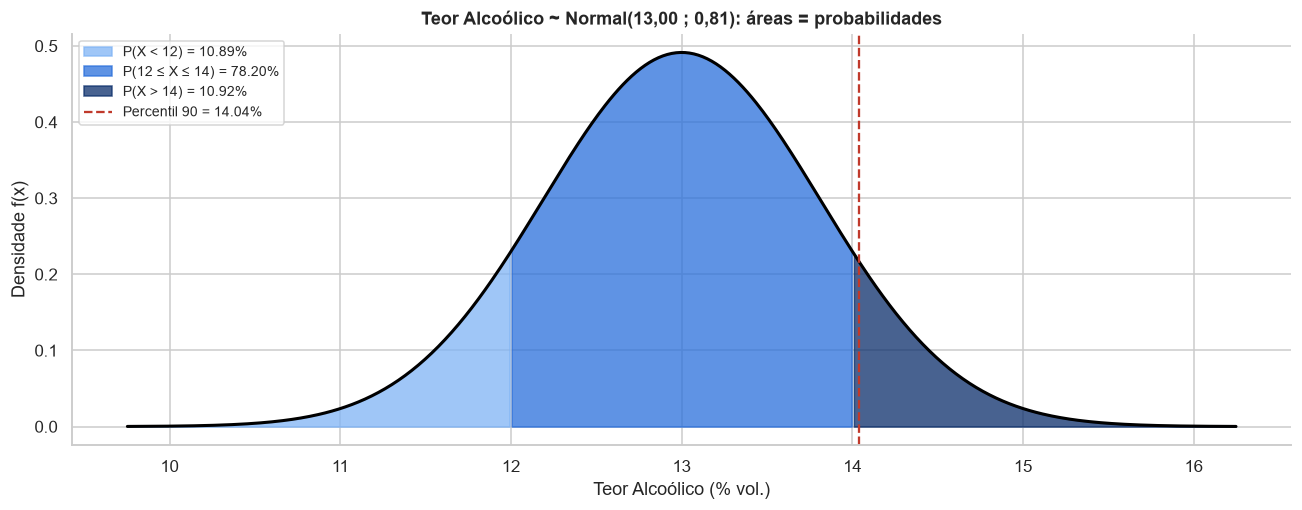

In [19]:
# ---------------------------------------------------------------------------
# Visualização das áreas de probabilidade na curva Normal
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.linspace(mu_alc - 4 * sd_alc, mu_alc + 4 * sd_alc, 500)
ax.plot(x, normal_alc.pdf(x), color="black", linewidth=2)

regioes = [(x < 12, "#7fb3f5", f"P(X < 12) = {normal_alc.cdf(12):.2%}"),
           ((x >= 12) & (x <= 14), "#2a6fdb", f"P(12 ≤ X ≤ 14) = {normal_alc.cdf(14) - normal_alc.cdf(12):.2%}"),
           (x > 14, "#0b2e6b", f"P(X > 14) = {normal_alc.sf(14):.2%}")]
for mascara, cor, rotulo in regioes:
    ax.fill_between(x, normal_alc.pdf(x), where=mascara, color=cor, alpha=0.75, label=rotulo)
ax.axvline(p90_teorico, color="#c0392b", linestyle="--", linewidth=1.5,
           label=f"Percentil 90 = {p90_teorico:.2f}%")
ax.set_title("Teor Alcoólico ~ Normal(13,00 ; 0,81): áreas = probabilidades")
ax.set_xlabel(NOMES["Alcohol"]); ax.set_ylabel("Densidade f(x)")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

# INTERPRETAÇÃO: em uma distribuição contínua, a probabilidade é a ÁREA sob a
# curva. As três áreas somam 100%: ~11% leves, ~78% na faixa comum e ~11%
# encorpados. Como a Normal é simétrica, as duas caudas têm áreas quase
# iguais — 12% e 14% estão praticamente à mesma distância da média (13%).

#### Cálculos complementares — Distribuição Binomial e Teorema Central do Limite

Duas aplicações que partem do modelo Normal:

- **Binomial:** em **10 sorteios independentes com reposição**, cada vinho corresponde a um ensaio com probabilidade de sucesso $p = P(X > 14)$. O número de vinhos acima de 14% segue $Y \sim Binomial(n=10, p)$.
- **Teorema Central do Limite (TCL):** sob amostragem independente, aproximamos a distribuição da **média** de 30 vinhos por $\bar{X} \sim N(\mu, \sigma/\sqrt{30})$. Útil, por exemplo, para um controle de qualidade de lote.

,P(Y = k),P(Y ≤ k)
k,,
0,0.3148,0.3148
1,0.3857,0.7005
2,0.2127,0.9132
3,0.0695,0.9827
4,0.0149,0.9976
5,0.0022,0.9998


P(Y = 0)  -> nenhum vinho acima de 14%: 31.48%
P(Y ≥ 2)  -> pelo menos 2 acima de 14%: 29.95%
E(Y) = n·p = 1.09 vinhos esperados acima de 14%

Erro-padrão da média (n=30): 0.1482
P(média de 30 vinhos > 13,2%) = 8.93%


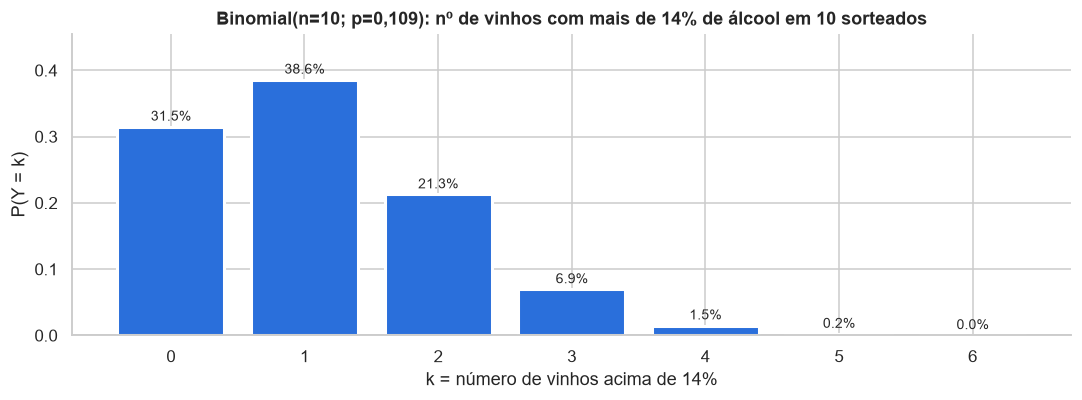

In [20]:
# ---------------------------------------------------------------------------
# Binomial: nº de vinhos com mais de 14% em uma amostra de 10 vinhos
# ---------------------------------------------------------------------------
p_sucesso = normal_alc.sf(14)                     # p = P(X > 14) = 10,92%
binom_alc = stats.binom(n=10, p=p_sucesso)

k_vals = np.arange(0, 11)
tabela_binom = pd.DataFrame({"k": k_vals, "P(Y = k)": binom_alc.pmf(k_vals),
                             "P(Y ≤ k)": binom_alc.cdf(k_vals)}).set_index("k")
display(tabela_binom.head(6).style.format("{:.4f}"))

print(f"P(Y = 0)  -> nenhum vinho acima de 14%: {binom_alc.pmf(0):.2%}")
print(f"P(Y ≥ 2)  -> pelo menos 2 acima de 14%: {binom_alc.sf(1):.2%}")
print(f"E(Y) = n·p = {binom_alc.mean():.2f} vinhos esperados acima de 14%")

# ---------------------------------------------------------------------------
# TCL: probabilidade de a MÉDIA de 30 vinhos passar de 13,2%
# ---------------------------------------------------------------------------
erro_padrao = sd_alc / np.sqrt(30)                # σ/√n
p_media = stats.norm(mu_alc, erro_padrao).sf(13.2)
print(f"\nErro-padrão da média (n=30): {erro_padrao:.4f}")
print(f"P(média de 30 vinhos > 13,2%) = {p_media:.2%}")

# Gráfico da distribuição Binomial
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(k_vals[:7], binom_alc.pmf(k_vals[:7]), color=COR["Alcohol"], edgecolor="white", linewidth=2)
for k, pk in zip(k_vals[:7], binom_alc.pmf(k_vals[:7])):
    ax.annotate(f"{pk:.1%}", (k, pk), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_title("Binomial(n=10; p=0,109): nº de vinhos com mais de 14% de álcool em 10 sorteados")
ax.set_xlabel("k = número de vinhos acima de 14%"); ax.set_ylabel("P(Y = k)")
ax.set_ylim(0, binom_alc.pmf(k_vals).max() * 1.18)
plt.tight_layout(); plt.show()

# INTERPRETAÇÃO:
# - Binomial: em uma degustação de 10 vinhos sorteados, esperamos ~1,09 vinho
#   acima de 14%. A chance de NENHUM passar de 14% é de 31,48%, e a de pelo
#   menos 2 passarem é de 29,95%. Ou seja: vinhos muito alcoólicos aparecem,
#   mas raramente em grande número numa amostra pequena.
# - TCL: a média de 30 vinhos varia muito MENOS que um vinho individual
#   (erro-padrão 0,15 contra desvio-padrão 0,81). Por isso, a chance de a média
#   de um lote de 30 vinhos passar de 13,2% é de só 8,93%. Se isso acontecer em
#   um lote real, é sinal de que o lote tem mais vinhos alcoólicos que o normal.

### 5.2 Ácido Málico — Distribuição Log-Normal

**Por que não Normal?** A variável é fortemente assimétrica (assimetria = +1,04) e **só assume valores positivos**. A Normal é simétrica e se estende até −∞, então:

1. Subestimaria a cauda direita e superestimaria a esquerda;
2. Daria probabilidade positiva a **concentrações negativas de ácido**, o que é fisicamente impossível.

Candidatas naturais para dados positivos e assimétricos à direita: **Log-Normal** e **Gama**. Comparamos as três pelo **AIC** (Critério de Informação de Akaike — quanto **menor**, melhor o equilíbrio entre ajuste e simplicidade) e pelo teste **KS**.

In [21]:
# ---------------------------------------------------------------------------
# Comparação de modelos candidatos para o Ácido Málico
# ---------------------------------------------------------------------------
candidatos = {
    "Normal":     stats.norm(*stats.norm.fit(acido)),
    "Log-Normal": stats.lognorm(*stats.lognorm.fit(acido)),   # (forma σ, loc, escala e^μ)
    "Gama":       stats.gamma(*stats.gamma.fit(acido)),
}
n_param = {"Normal": 2, "Log-Normal": 3, "Gama": 3}

resultado = []
for nome, dist in candidatos.items():
    log_vero = dist.logpdf(acido).sum()                       # log-verossimilhança
    ks = stats.kstest(acido, dist.cdf)
    resultado.append({"Modelo": nome, "AIC": 2 * n_param[nome] - 2 * log_vero,
                      "KS estatística": ks.statistic,
                      "P(X < 0) [impossível]": dist.cdf(0)})
comparacao_modelos = pd.DataFrame(resultado).set_index("Modelo").sort_values("AIC")
display(comparacao_modelos)

lognorm_mal = candidatos["Log-Normal"]
forma_s, loc_mal, escala_mal = lognorm_mal.args
print(f"Modelo escolhido: Log-Normal(σ = {forma_s:.4f}, deslocamento = {loc_mal:.4f}, "
      f"escala = {escala_mal:.4f})")
print(f"Shapiro-Wilk nos DADOS ORIGINAIS: p = {stats.shapiro(acido).pvalue:.2e} "
      f"-> normalidade claramente rejeitada")

# INTERPRETAÇÃO — ESCOLHA DO MODELO:
# A Normal tem AIC de aproximadamente 547,6 e atribui probabilidade a valores
# negativos. Log-Normal (AIC 486,3) e Gama (AIC 486,5) apresentam ajustes próximos.
# Escolhemos a Log-Normal pelo menor AIC, mas a diferença de cerca de 0,2 é
# pequena e não sustenta superioridade forte sobre a Gama.
# A estatística KS é usada descritivamente, sem p-valor para parâmetros
# estimados na mesma amostra. QQ-plot e probabilidades empíricas mostram
# desvios do ajuste, especialmente na faixa intermediária de ácido málico.


,AIC,KS estatística,P(X < 0) [impossível]
Modelo,,,
Log-Normal,486.3440,0.1034,0.0000
Gama,486.4999,0.1204,0.0000
Normal,547.5760,0.1917,0.0180


Modelo escolhido: Log-Normal(σ = 0.5898, deslocamento = 0.4622, escala = 1.5813)
Shapiro-Wilk nos DADOS ORIGINAIS: p = 2.95e-10 -> normalidade claramente rejeitada


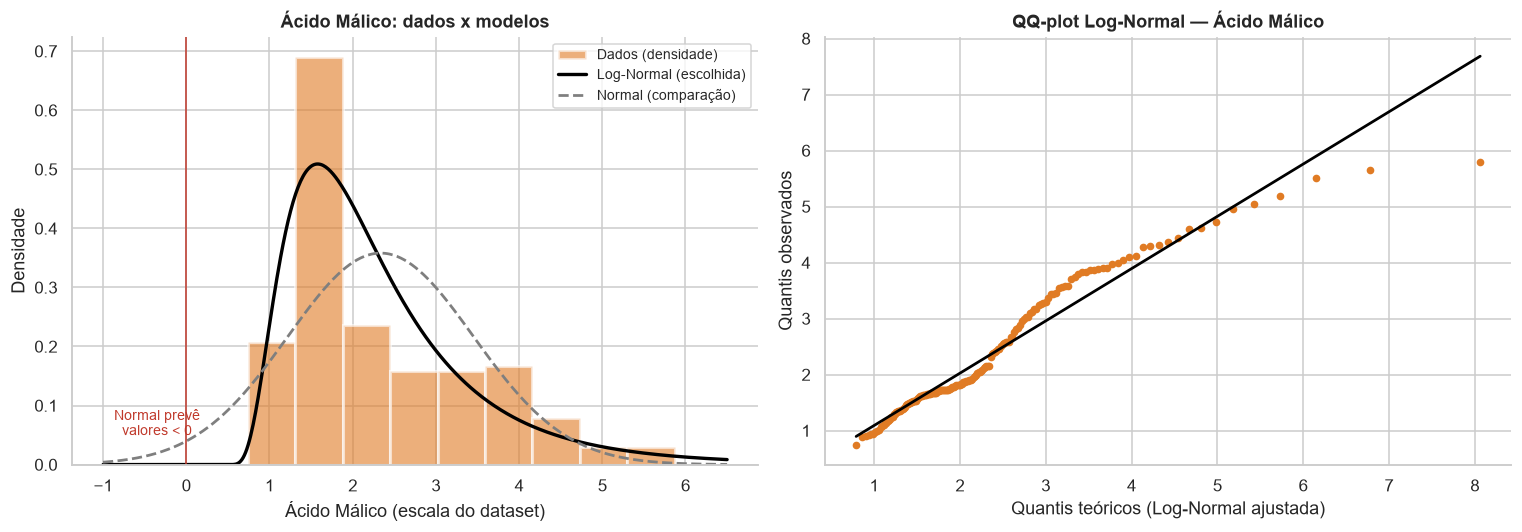

In [22]:
# ---------------------------------------------------------------------------
# Gráficos de aderência: histograma x Normal x Log-Normal | QQ-plot Log-Normal
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(acido, bins=lim_mal, density=True, color=COR["Malic.acid"], alpha=0.6,
        edgecolor="white", linewidth=2, label="Dados (densidade)")
x = np.linspace(-1, 6.5, 500)
ax.plot(x, lognorm_mal.pdf(x), color="black", linewidth=2.2, label="Log-Normal (escolhida)")
ax.plot(x, candidatos["Normal"].pdf(x), color="#7f7f7f", linewidth=1.8, linestyle="--",
        label="Normal (comparação)")
ax.axvline(0, color="#c0392b", linewidth=1)
ax.annotate("Normal prevê\nvalores < 0", (-0.35, 0.05), color="#c0392b", fontsize=9, ha="center")
ax.set_title("Ácido Málico: dados x modelos")
ax.set_xlabel(NOMES["Malic.acid"]); ax.set_ylabel("Densidade"); ax.legend(fontsize=9)

ax = axes[1]
stats.probplot(acido, dist=stats.lognorm, sparams=lognorm_mal.args, plot=ax)
ax.get_lines()[0].set(color=COR["Malic.acid"], markersize=4)
ax.get_lines()[1].set(color="black", linewidth=1.8)
ax.set_title("QQ-plot Log-Normal — Ácido Málico")
ax.set_xlabel("Quantis teóricos (Log-Normal ajustada)"); ax.set_ylabel("Quantis observados")
plt.tight_layout(); plt.show()

# INTERPRETAÇÃO:
# - A Log-Normal acompanha o pico à esquerda e a cauda longa à direita; a
#   Normal (tracejada) coloca o pico no lugar errado e "vaza" para valores
#   negativos.
# - No QQ-plot, os pontos seguem bem a reta até ~2,5. Entre 2,5 e 4
#   ficam ACIMA da reta — é o "platô" do segundo grupo de vinhos ácidos visto
#   na tabela de frequências. Acima de 5 ficam ABAIXO da reta: a cauda
#   real é mais curta que a do modelo (o maior valor observado é 5,80).
#   Esses desvios indicam limitações do ajuste e são discutidos na
#   comparação entre probabilidades teóricas e empíricas.

#### Cálculos probabilísticos — Ácido Málico

| # | Pergunta de negócio | Cálculo |
|---|---|---|
| 1 | Qual a chance de um vinho ser **muito ácido** (mais de 3)? | $P(X > 3)$ |
| 2 | Qual a chance de um vinho ter **baixa acidez** (menos de 2)? | $P(X < 2)$ |
| 3 | Qual a chance de estar na **faixa típica** de 1,5 a 2,5? | $P(1{,}5 \le X \le 2{,}5)$ |
| 4 | Qual a chance de um vinho ser **extremamente ácido** (mais de 4)? | $P(X > 4)$ |
| 5 | Em **10 sorteios independentes com reposição**, qual a chance de **pelo menos 3** serem muito ácidos? | Binomial |

In [23]:
# ---------------------------------------------------------------------------
# Cálculos probabilísticos com a Log-Normal: teórico x empírico x Normal
# ---------------------------------------------------------------------------
normal_mal = candidatos["Normal"]
eventos = {
    "P(X > 3)":          (lambda d: d.sf(3),                  (acido > 3).mean()),
    "P(X < 2)":          (lambda d: d.cdf(2),                 (acido < 2).mean()),
    "P(1,5 ≤ X ≤ 2,5)":  (lambda d: d.cdf(2.5) - d.cdf(1.5),  acido.between(1.5, 2.5).mean()),
    "P(X > 4)":          (lambda d: d.sf(4),                  (acido > 4).mean()),
}
calculos_mal = pd.DataFrame({
    "Teórica (Log-Normal)": {k: f(lognorm_mal) for k, (f, _) in eventos.items()},
    "Empírica (dados)":     {k: emp for k, (_, emp) in eventos.items()},
    "Se usássemos a Normal": {k: f(normal_mal) for k, (f, _) in eventos.items()},
})
calculos_mal["Erro Log-Normal (p.p.)"] = (calculos_mal["Teórica (Log-Normal)"] - calculos_mal["Empírica (dados)"]) * 100
calculos_mal["Erro Normal (p.p.)"] = (calculos_mal["Se usássemos a Normal"] - calculos_mal["Empírica (dados)"]) * 100
display(calculos_mal.style.format({c: "{:.2%}" for c in calculos_mal.columns[:3]} |
                                  {c: "{:+.2f}" for c in calculos_mal.columns[3:]}))

# ---------------------------------------------------------------------------
# Binomial: nº de vinhos "muito ácidos" (> 3) em 10 vinhos sorteados
# ---------------------------------------------------------------------------
p_acido = lognorm_mal.sf(3)
binom_mal = stats.binom(n=10, p=p_acido)
print(f"p = P(X > 3) pela Log-Normal = {p_acido:.4f}")
print(f"P(Y ≥ 3) = 1 - P(Y ≤ 2) = {binom_mal.sf(2):.2%}")
print(f"E(Y) = {binom_mal.mean():.2f} vinhos muito ácidos esperados em 10")

# INTERPRETAÇÃO — CÁLCULOS COM O ÁCIDO MÁLICO:
# 1) P(X > 3) = 21,13% (modelo) x 26,40% (dados): cerca de 1 em cada 4-5
#    vinhos é "muito ácido". O modelo subestima um pouco, pois o grupo de
#    vinhos ácidos (cultivar 3) engrossa essa faixa.
# 2) P(X < 2) = 48,11% x 56,18%: pouco mais da metade dos vinhos tem baixa
#    acidez (< 2).
# 3) P(1,5 ≤ X ≤ 2,5) = 42,88% x 47,19%: a faixa típica concentra quase metade.
# 4) P(X > 4) = 8,61% x 9,55%: acidez extrema é rara (~1 em cada 10 vinhos) e
#    aqui o modelo acerta bem a cauda (erro < 1 p.p.).
# 5) Binomial: em 10 vinhos sorteados esperamos ~2,1 muito ácidos, e a chance
#    de pelo menos 3 deles serem muito ácidos é de 35,65%.
#
# Log-Normal x Normal: a Normal erra MUITO MAIS em P(X < 2) (-18,0 p.p.
# contra -8,1 p.p.) e em P(1,5 ≤ X ≤ 2,5) (-14,0 contra -4,3 p.p.), e ainda
# prevê acidez negativa. Em P(X > 3) a Normal parece
# aproximar melhor esse evento (+1,2 p.p.), mas isso não se repete em
# todos os intervalos: ela desloca a curva para a
# direita e erra o formato — o que aparece nos outros eventos. Conclusão: a Log-Normal tem menor AIC entre os candidatos, e seus resultados
# devem ser lidos como aproximações (erro de até ~8 p.p.), enquanto a
# proporção empírica é a referência mais fiel para esta amostra.

,Teórica (Log-Normal),Empírica (dados),Se usássemos a Normal,Erro Log-Normal (p.p.),Erro Normal (p.p.)
P(X > 3),21.13%,26.40%,27.57%,-5.28,+1.16
P(X < 2),48.11%,56.18%,38.14%,-8.07,-18.04
"P(1,5 ≤ X ≤ 2,5)",42.88%,47.19%,33.20%,-4.31,-13.99
P(X > 4),8.61%,9.55%,6.77%,-0.94,-2.78


p = P(X > 3) pela Log-Normal = 0.2113
P(Y ≥ 3) = 1 - P(Y ≤ 2) = 35.65%
E(Y) = 2.11 vinhos muito ácidos esperados em 10


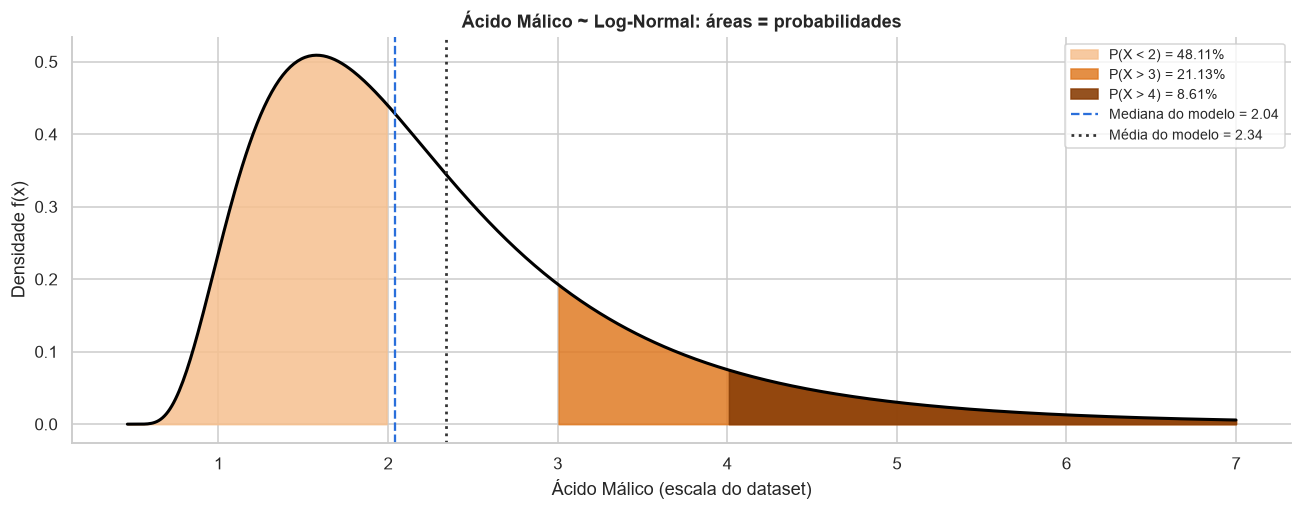

In [24]:
# ---------------------------------------------------------------------------
# Visualização das áreas de probabilidade na Log-Normal
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.linspace(loc_mal + 0.001, 7, 600)
ax.plot(x, lognorm_mal.pdf(x), color="black", linewidth=2)
ax.fill_between(x, lognorm_mal.pdf(x), where=x < 2, color="#f6c08f", alpha=0.85,
                label=f"P(X < 2) = {lognorm_mal.cdf(2):.2%}")
ax.fill_between(x, lognorm_mal.pdf(x), where=x > 3, color="#e07b24", alpha=0.85,
                label=f"P(X > 3) = {lognorm_mal.sf(3):.2%}")
ax.fill_between(x, lognorm_mal.pdf(x), where=x > 4, color="#8a3f08", alpha=0.9,
                label=f"P(X > 4) = {lognorm_mal.sf(4):.2%}")
ax.axvline(lognorm_mal.median(), color="#2a6fdb", linestyle="--", linewidth=1.5,
           label=f"Mediana do modelo = {lognorm_mal.median():.2f}")
ax.axvline(lognorm_mal.mean(), color="#333333", linestyle=":", linewidth=1.8,
           label=f"Média do modelo = {lognorm_mal.mean():.2f}")
ax.set_title("Ácido Málico ~ Log-Normal: áreas = probabilidades")
ax.set_xlabel(NOMES["Malic.acid"]); ax.set_ylabel("Densidade f(x)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

# INTERPRETAÇÃO: diferente da Normal, a curva é ASSIMÉTRICA — sobe rápido,
# atinge o pico por volta de 1,6 e desce devagar. A média do modelo (2,34)
# fica à direita da mediana (2,04), reproduzindo o mesmo padrão dos dados
# (média 2,34 > mediana 1,87). As áreas mostram que a cauda direita é longa:
# mesmo acima de 4 ainda há ~8,6% de probabilidade.

### 5.3 Probabilidade condicional por cultivar

Usando a coluna de cultivar (disponível no arquivo do GitHub), verificamos **de quais cultivares** vêm os vinhos dos eventos analisados. Isso mostra, em termos probabilísticos, por que um algoritmo de agrupamento consegue separar os vinhos.

In [25]:
# ---------------------------------------------------------------------------
# Probabilidades condicionais: P(cultivar | evento)
# ---------------------------------------------------------------------------
if "Wine" in df.columns:
    condicional = pd.DataFrame({
        "P(cultivar | álcool > 14%)":   df.loc[alcool > 14, "Wine"].value_counts(normalize=True),
        "P(cultivar | ácido > 3)":  df.loc[acido > 3, "Wine"].value_counts(normalize=True),
        "P(cultivar) geral":            df["Wine"].value_counts(normalize=True),
    }).fillna(0).sort_index()
    condicional.index.name = "Cultivar"
    display(condicional.style.format("{:.2%}"))

# INTERPRETAÇÃO:
# - Dos 22 vinhos com mais de 14% de álcool, 86,36% (19) são do cultivar 1 e
#   NENHUM é do cultivar 2 — embora o cultivar 1 represente só 33,15% do total.
# - Dos 47 vinhos com mais de 3 de ácido málico, 63,83% (30) são do
#   cultivar 3, que representa apenas 26,97% do total.
# - Ou seja: conhecer o teor alcoólico e a acidez muda muito a probabilidade
#   de o vinho pertencer a cada grupo. Essas duas variáveis têm poder de
#   separação e ajudam a caracterizar os perfis dos cultivares.

,P(cultivar | álcool > 14%),P(cultivar | ácido > 3),P(cultivar) geral
Cultivar,,,
1,86.36%,14.89%,33.15%
2,0.00%,21.28%,39.89%
3,13.64%,63.83%,26.97%


## 6. Conclusões

| Aspecto | Teor Alcoólico (`Alcohol`) | Ácido Málico (`Malic.acid`) |
|---|---|---|
| **Forma** | Simétrica (assimetria −0,05), achatada (curtose −0,85) | Assimétrica à direita (assimetria +1,04) |
| **Valor típico** | Média ≈ Mediana ≈ **13,0%** | Mediana = **1,87** (média 2,34 inflada pela cauda) |
| **Dispersão** | Baixa — CV = 6,24% (vinhos homogêneos) | Alta — CV = 47,82% (vinhos heterogêneos) |
| **Quartis** | Q1 = 12,36 · Q2 = 13,05 · Q3 = 13,68 | Q1 = 1,60 · Q2 = 1,87 · Q3 = 3,08 |
| **Outliers** | Nenhum | 3 (5,51 · 5,65 · 5,80), mantidos sem evidência de erro |
| **Modelo probabilístico** | **Normal(13,00; 0,81)** — aproximação adequada | **Log-Normal** — menor AIC, próximo ao da Gama |
| **Destaques** | P(X > 14%) ≈ 11% · P(12 ≤ X ≤ 14) ≈ 78% | P(X > 3) ≈ 21% (26% nos dados) · P(X < 2) ≈ 48% |

**Principais aprendizados:**

1. **A forma da distribuição decide a análise.** Para a variável simétrica, média e Normal funcionam bem; para a assimétrica, a mediana descreve melhor o típico e é preciso um modelo assimétrico (Log-Normal).
2. **Todo modelo deve ser validado contra os dados.** A comparação teórico × empírico mostrou que a Normal difere em até ~1,5 p.p. nos três eventos de teor alcoólico analisados, e que a Log-Normal, embora tenha o menor AIC entre os candidatos, erra até ~8 p.p. para o ácido málico.
3. **A heterogeneidade entre cultivares contribui para os desvios:** o dataset mistura **três cultivares** com perfis diferentes (seções 4.5 e 5.3). Essa heterogeneidade também fundamenta a análise de agrupamento com K-means.

---
*Ambiente: Python 3 · pandas · numpy · scipy · matplotlib · seaborn. Dados: dataset WINES (UCI / GitHub gist tijptjik, 178 vinhos, 13 medições químicas).*

Referência metodológica: [SciPy — ajuste de distribuições e testes de aderência](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html).